In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

In [2]:
data_path = Path("data/26MAG_HW_1_v3.xls")

columns = [
    "Возраст",
    "Иждивенцы",
    "Доход",
    "Срок проживания",
    "Стоимость автомобиля",
    "Размер кредита",
]

df = pd.read_excel(
    data_path,
    header=None,
    names=columns,
)

print(df)
print(f"\nКлиентов: {df.shape[0]}, признаков: {df.shape[1]}")

    Возраст  Иждивенцы    Доход  Срок проживания  Стоимость автомобиля  \
0      40.0        1.0   2900.0             11.0                2000.0   
1      56.0        4.0  16400.0             20.0               20000.0   
2      55.0        4.0  22600.0             19.0               26000.0   
3       NaN        2.0   6300.0             13.0                7000.0   
4      54.0        4.0  25400.0             18.0               28000.0   
5      51.0        3.0  17600.0             17.0               20000.0   
6      40.0        2.0  12900.0             10.0               13000.0   
7      51.0        3.0   7100.0             17.0                9000.0   
8      44.0        2.0      NaN             13.0               17000.0   
9      49.0        3.0  14900.0             16.0               17000.0   
10     35.0        NaN  29400.0              6.0               29000.0   
11     21.0        3.0   8200.0             11.0               48000.0   
12     32.0        2.0  37100.0       

### 1.1 Основные характеристики признаков

При вычислении пропуски исключаются отдельно для каждого признака.

In [3]:
stats = pd.DataFrame(
    {
        "# наблюдений": df.count(),
        "# пропусков": df.isna().sum(),
        "Среднее": df.mean(skipna=True),
        "Стандартное отклонение": df.std(skipna=True),
        "Медиана": df.median(skipna=True),
        "Q1 (25%)": df.quantile(0.25),
        "Q3 (75%)": df.quantile(0.75),
    }
)

stats.round(2)

,# наблюдений,# пропусков,Среднее,Стандартное отклонение,Медиана,Q1 (25%),Q3 (75%)
Возраст,40,2,38.78,9.05,39.0,31.75,44.0
Иждивенцы,40,2,2.00,1.09,2.0,1.00,3.0
Доход,40,2,19360.00,10264.97,19450.0,12400.00,27050.0
Срок проживания,40,2,10.20,4.97,10.5,5.00,13.0
Стоимость автомобиля,40,2,21325.00,11899.98,20000.0,14750.00,28000.0
Размер кредита,40,2,196025.00,97304.30,195000.0,149500.00,261750.0


### 1.2. Гистограммы признаков

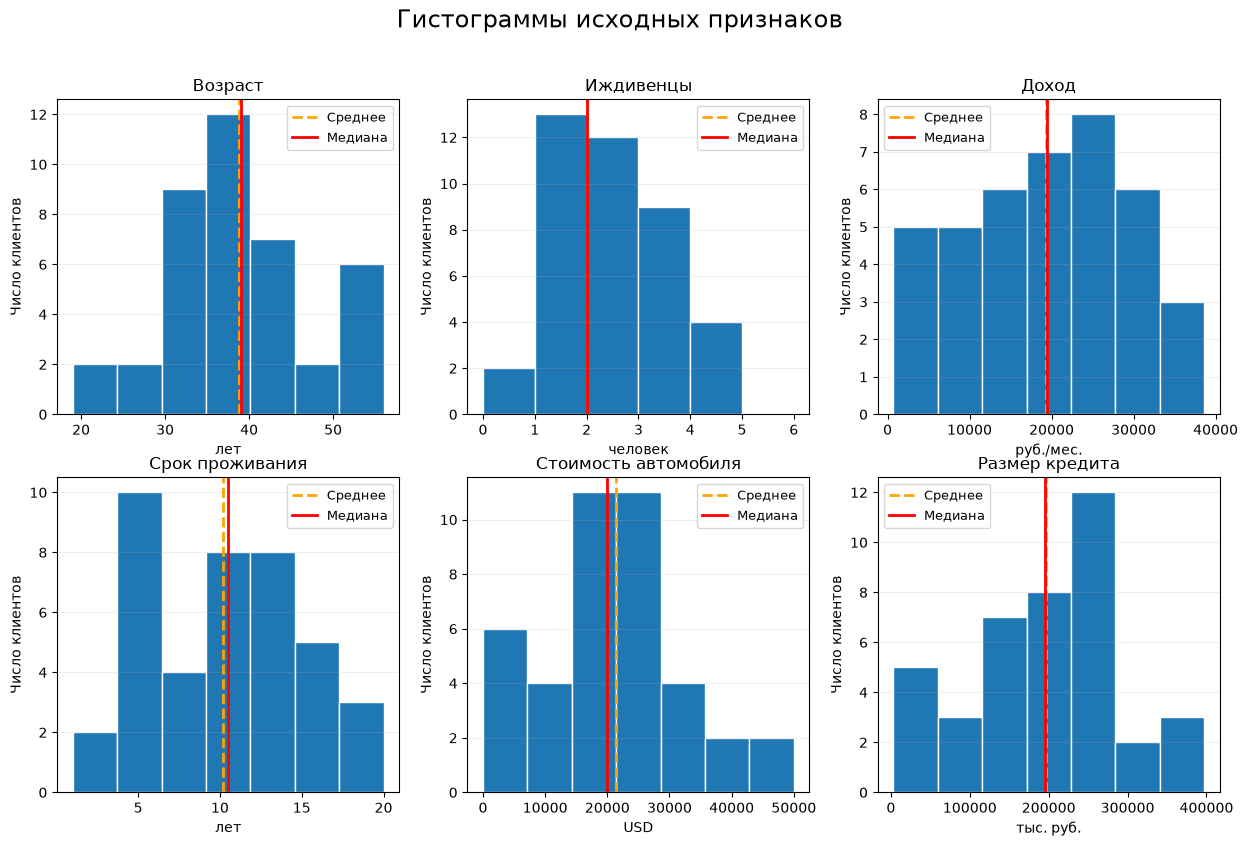

In [4]:
units = {
    "Возраст": "лет",
    "Иждивенцы": "человек",
    "Доход": "руб./мес.",
    "Срок проживания": "лет",
    "Стоимость автомобиля": "USD",
    "Размер кредита": "тыс. руб.",
}

fig_hist, axes = plt.subplots(2, 3, figsize=(15, 9))
fig_hist.suptitle("Гистограммы исходных признаков", fontsize=17)

for ax, column in zip(axes.flat, df.columns):
    values = df[column].dropna()
    if column == "Иждивенцы":
        ax.hist(values, bins=range(0, 7), edgecolor="white")
    else:
        ax.hist(values, bins="auto", edgecolor="white")
    ax.axvline(
        values.mean(), color="orange", linestyle="--", linewidth=2, label="Среднее"
    )
    ax.axvline(values.median(), color="red", linewidth=2, label="Медиана")
    ax.set_title(f"{column}")
    ax.set_xlabel(units[column])
    ax.set_ylabel("Число клиентов")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(fontsize=9)

plt.show()

На графиках выше видно, что данные распределены неравномерно: они скорее сконцентрированы около среднего значения.
Это особенно заметно во всех случаях, кроме срока проживания.
В его случае гистограмма имеет два явных пика: около 4–6 и 10–14 лет.

Распределения не выглядят строго симметричными. По этим гистограммам нельзя точно считать их нормальными: наличие пика около среднего само по себе этого не доказывает. Особенно при таком низком размере выборки.

### 2. Заполнение пропусков

Для заполнения пропусков используем медиану каждого признака.
Вычислим ее по непустым значениям столбца и подставляем вместо `NaN`.

Причины выбора медианы:
- В данных есть крайние значения, например дорогие автомобили. Медиана
  менее чувствительна к их величине, чем среднее.
- Нормальность распределений не доказана. Медианное заполнение
  не требует предположения о нормальном распределении.
- Пропусков немного: в каждом признаке всего 2.

In [5]:
missing_before = df.isna().sum()
medians = df.median(skipna=True)

df_filled = df.fillna(medians)

imputation_summary = pd.DataFrame(
    {
        "Медиана для заполнения": medians,
        "Пропусков до": missing_before,
        "Пропусков после": df_filled.isna().sum(),
    }
)
imputation_summary

,Медиана для заполнения,Пропусков до,Пропусков после
Возраст,39.0,2,0
Иждивенцы,2.0,2,0
Доход,19450.0,2,0
Срок проживания,10.5,2,0
Стоимость автомобиля,20000.0,2,0
Размер кредита,195000.0,2,0


In [6]:
df_filled

,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита
0,40.0,1.0,2900.0,11.0,2000.0,25000.0
1,56.0,4.0,16400.0,20.0,20000.0,184000.0
2,55.0,4.0,22600.0,19.0,26000.0,246000.0
3,39.0,2.0,6300.0,13.0,7000.0,65000.0
4,54.0,4.0,25400.0,18.0,28000.0,274000.0
5,51.0,3.0,17600.0,17.0,20000.0,190000.0
6,40.0,2.0,12900.0,10.0,13000.0,127000.0
7,51.0,3.0,7100.0,17.0,9000.0,82000.0
8,44.0,2.0,19450.0,13.0,17000.0,165000.0
9,49.0,3.0,14900.0,16.0,17000.0,159000.0


### 3. Определение и удаление выбросов

Используем правило Тьюки на основе межквартильного размаха.

Для каждого признака вычисляем первый и третий квартили, затем:

$$IQR = Q_3 - Q_1,$$
$$L = Q_1 - 1.5\cdot IQR, \qquad U = Q_3 + 1.5\cdot IQR.$$

Значение считаем выбросом, если оно строго меньше $L$ или больше $U$.
Удаляем объект целиком, если хотя бы один из его признаков является
выбросом по этому правилу.

Причины выбора метода:
- Квартили менее чувствительны к крайним значениям, чем среднее и
  стандартное отклонение.
- Метод не требует предположения о нормальном распределении.

In [7]:
q1 = df_filled.quantile(0.25)
q3 = df_filled.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_features = df_filled.lt(lower_bound) | df_filled.gt(upper_bound)
outlier_objects = outlier_features.any(axis=1)

outlier_summary = pd.DataFrame(
    {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Нижняя граница": lower_bound,
        "Верхняя граница": upper_bound,
        "# выбросов": outlier_features.sum(),
    }
)
outlier_summary.round(2)

,Q1,Q3,IQR,Нижняя граница,Верхняя граница,# выбросов
Возраст,32.00,43.75,11.75,14.38,61.38,0
Иждивенцы,1.00,3.00,2.00,-2.00,6.00,0
Доход,13400.00,26800.00,13400.00,-6700.00,46900.00,0
Срок проживания,5.25,13.00,7.75,-6.38,24.62,0
Стоимость автомобиля,15250.00,27750.00,12500.00,-3500.00,46500.00,2
Размер кредита,152250.00,261000.00,108750.00,-10875.00,424125.00,0


In [8]:
df_outliers = df_filled.loc[outlier_objects].copy()
df_outliers["Признаки вне границ"] = outlier_features.loc[outlier_objects].apply(
    lambda row: ", ".join(row.index[row]),
    axis=1,
)
df_outliers

,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита,Признаки вне границ
11,21.0,3.0,8200.0,11.0,48000.0,250000.0,Стоимость автомобиля
32,19.0,2.0,8000.0,12.0,50000.0,200000.0,Стоимость автомобиля


In [9]:
df_clean = df_filled.loc[~outlier_objects].copy()

print(f"Удалено клиентов: {outlier_objects.sum()} из {len(df_filled)}")
print(f"Осталось клиентов: {len(df_clean)}")
df_clean

Удалено клиентов: 2 из 42
Осталось клиентов: 40


,Возраст,Иждивенцы,Доход,Срок проживания,Стоимость автомобиля,Размер кредита
0,40.0,1.0,2900.0,11.0,2000.0,25000.0
1,56.0,4.0,16400.0,20.0,20000.0,184000.0
2,55.0,4.0,22600.0,19.0,26000.0,246000.0
3,39.0,2.0,6300.0,13.0,7000.0,65000.0
4,54.0,4.0,25400.0,18.0,28000.0,274000.0
5,51.0,3.0,17600.0,17.0,20000.0,190000.0
6,40.0,2.0,12900.0,10.0,13000.0,127000.0
7,51.0,3.0,7100.0,17.0,9000.0,82000.0
8,44.0,2.0,19450.0,13.0,17000.0,165000.0
9,49.0,3.0,14900.0,16.0,17000.0,159000.0


Удалены строки 11 и 32. Стоимость их автомобилей равна
48000 и 50000 USD, что превышает верхнюю границу в 46500.
У остальных признаков выбросов нет.

### 9. Расстояния Чебышева и возможность точного размещения на плоскости

Каждый клиент представлен шестью признаками. После заполнения пропусков
и удаления выбросов осталось 40 клиентов.

Признаки имеют разные единицы и масштабы, поэтому сначала стандартизируем
каждый столбец:

$$\widetilde{x}_{ik} = \frac{x_{ik} - \overline{x}_k}{s_k},
\qquad s_k = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ik}-\overline{x}_k)^2}.$$

Здесь $\overline{x}_k$ — среднее признака, $s_k$ — стандартное отклонение. Стандартизированные значения показывают отклонение от среднего
в единицах стандартного отклонения.

Используем расстояние Чебышева между стандартизированными векторами:

$$d_{ij} = \max_k |\widetilde{x}_{ik} - \widetilde{x}_{jk}|.$$

Оно показывает максимальное различие по одному признаку.
Матрица $D=(d_{ij})$ симметрична, имеет нулевую диагональ и размер $40\times40$.


In [10]:
df_scaled = (df_clean - df_clean.mean()) / df_clean.std(ddof=0)
X_mds = df_scaled.to_numpy(dtype=float)

D_chebyshev = np.abs(X_mds[:, None, :] - X_mds[None, :, :]).max(axis=2)

client_ids = pd.Index(df_clean.index + 1)
distances_chebyshev = pd.DataFrame(
    D_chebyshev,
    index=client_ids,
    columns=client_ids,
)
print(f"Размер матрицы расстояний: {D_chebyshev.shape}\n\n")
print(distances_chebyshev.round(3).head())

Размер матрицы расстояний: (40, 40)


      1      2      3      4      5      6      7      8      9      10  ...  \
1  0.000  2.829  2.829  0.943  2.829  1.886  1.113  1.886  1.688  1.886  ...   
2  2.829  0.000  0.648  2.171  0.941  0.943  2.044  1.113  1.886  0.943  ...   
3  2.829  0.648  0.000  2.044  0.293  0.943  1.916  1.720  1.886  0.943  ...   
4  0.943  2.171  2.044  0.000  2.184  1.533  0.673  1.533  1.342  1.277  ...   
5  2.829  0.941  0.293  2.184  0.000  0.943  1.886  2.007  1.886  1.202  ...   

      32     34     35     36     37     38     39     40     41     42  
1  2.383  0.943  2.479  3.136  1.902  2.466  0.303  2.561  1.315  2.581  
2  3.064  1.886  3.959  1.838  2.451  2.299  2.829  3.268  2.299  3.321  
3  2.860  2.428  3.832  1.634  2.299  2.171  2.829  3.065  2.171  3.193  
4  1.965  0.506  2.451  2.630  1.510  2.048  0.943  2.214  0.928  2.234  
5  2.829  2.630  3.772  1.430  2.171  2.044  2.829  2.938  2.044  3.065  

[5 rows x 40 columns]


Проверим возможность точного размещения в $\mathbb{R}^2$.

Для каждого клиента должна существовать точка $y_i=(u_i,v_i)$, такая что:

$$\|y_i-y_j\|_2 = \sqrt{(u_i-u_j)^2+(v_i-v_j)^2}=d_{ij}.$$

Пусть $Y$ - искомая матрица координат: каждая строка соответствует клиенту,
столбцы - координатам на плоскости. Матрица $YY^T$ содержит скалярные
произведения $y_i^Ty_j$. Их связь с исходными известными расстояниями:

$$d_{ij}^2 = \|y_i\|_2^2 + \|y_j\|_2^2 - 2y_i^Ty_j.$$

Обозначим
$S_{ij}=d_{ij}^2$ и $a_i=\|y_i\|_2^2$, $\mathbf{1}$ - столбец из $n$ единиц.. Тогда та же формула в матричной записи:

$$S = a\mathbf{1}^T + \mathbf{1}a^T - 2YY^T.$$

Перенос всех точек не меняет расстояния, поэтому выбираем начало координат
в их среднем. Центрирующая матрица

$$H = I_n - \frac{1}{n}\mathbf{1}\mathbf{1}^T$$

вычитает среднее из каждого столбца координат: $Y_c=HY$.
Здесь $I_n$ - единичная матрица, $\mathbf{1}$ - столбец из $n$ единиц.
Имеем $H\mathbf{1}=0$, $\mathbf{1}^TH=0$ и $H^T=H$.

Умножаем формулу для $S$ слева и справа на $H$:

$$HSH = Ha\mathbf{1}^TH + H\mathbf{1}a^TH - 2HYY^TH.$$

Первое слагаемое исчезает благодаря $\mathbf{1}^TH=0$, второе - благодаря
$H\mathbf{1}=0$. Одного умножения было бы недостаточно: одно из слагаемых
с квадратами длин осталось бы. Поэтому:

$$HSH = -2(HY)(HY)^T = -2Y_cY_c^T,$$
$$B = -\frac12 HSH = -\frac12 HD^{(2)}H.$$

Здесь $D^{(2)}_{ij}=d_{ij}^2$: матрица двадратов исходных длин.

Необходимость условий:

1. $B$ должна быть положительно полуопределена. Для любого вектора $c$:

   $$c^TBc=c^TY_cY_c^Tc=(Y_c^Tc)^T(Y_c^Tc)=\|Y_c^Tc\|_2^2\geq0.$$

   Квадрат длины неотрицателен. Для симметричной матрицы это равносильно
   неотрицательности всех собственных значений.
2. $\operatorname{rank}(B)\leq2$. У $Y_c$ только два столбца, поэтому:

   $$\operatorname{rank}(B)=\operatorname{rank}(Y_cY_c^T)
   =\operatorname{rank}(Y_c)\leq2.$$

Достаточность условий: 

Пусть $B$ положительно полуопределена и имеет
ранг $r\leq2$. Выполняем спектральное разложение $B=QTQ^T$.
В $Q_r$ оставляем собственные векторы для $r$ положительных собственных
значений, в $T_r$ - сами эти значения. Строим координаты:

$$Y_c=Q_rT_r^{1/2}.$$

Тогда $Y_cY_c^T=Q_rT_rQ_r^T=B$. У $Y_c$ не больше двух столбцов,
поэтому полученные точки размещаются на плоскости.

Проверим, что они сохраняют исходные расстояния. Пусть $m_i$ - среднее
строки $S$, $g$ - среднее всех элементов $S$. Двойное центрирование дает:

$$B_{ij}=-\frac12(S_{ij}-m_i-m_j+g).$$

Так как $S_{ii}=0$, имеем $B_{ii}=m_i-g/2$. Поэтому:

$$\|y_{c,i}-y_{c,j}\|_2^2=B_{ii}+B_{jj}-2B_{ij}=S_{ij}=d_{ij}^2.$$

Следовательно, оба условия вместе необходимы и достаточны для точного
размещения на евклидовой плоскости.


In [11]:
n_clients = len(df_clean)
H = np.eye(n_clients) - np.ones((n_clients, n_clients)) / n_clients
B = -0.5 * H @ (D_chebyshev**2) @ H
B = (B + B.T) / 2

eigenvalues = np.linalg.eigvalsh(B)
eps = 1e-10 * np.max(np.abs(eigenvalues))

n_positive = np.count_nonzero(eigenvalues > eps)
n_negative = np.count_nonzero(eigenvalues < -eps)
n_zero = np.count_nonzero(np.abs(eigenvalues) <= eps)
gram_rank = n_positive + n_negative
is_psd = n_negative == 0
can_embed_2d = is_psd and gram_rank <= 2

print(f"Минимальное собственное значение: {eigenvalues.min():.6f}")
print(f"Максимальное собственное значение: {eigenvalues.max():.6f}")
print(f"Положительных значений: {n_positive}")
print(f"Отрицательных значений: {n_negative}")
print(f"Нулевых значений: {n_zero}")
print(f"Численный ранг B: {gram_rank}")
print(f"B положительно полуопределена: {is_psd}")
print(f"Точное размещение в размерности 2 возможно: {can_embed_2d}")

Минимальное собственное значение: -7.771122
Максимальное собственное значение: 39.772768
Положительных значений: 22
Отрицательных значений: 17
Нулевых значений: 1
Численный ранг B: 39
B положительно полуопределена: False
Точное размещение в размерности 2 возможно: False


Матрица расстояний Чебышева имеет размер $40\times40$.

У матрицы $B$ 22 положительных, 17 отрицательных и 1 нулевое собственное
значение. Минимальное равно примерно −7.771. Ранг $B$ равен 39.

Точное размещение на евклидовой плоскости невозможно: $B$ не является
положительно полуопределенной, и ее ранг больше 2.
Отрицательные собственные значения исключают точное евклидово размещение
даже в большей размерности.

### 10. Карта клиентов: классический MDS

Используем классический MDS. На вход он получает матрицу
расстояний между объектами, а на выходе дает координаты объектов в пространстве
заданной размерности.

1. Берем расстояния Чебышева из пункта 9.
2. Используем полученную там матрицу $B$.
3. Находим собственные значения и собственные векторы $B$.
4. Оставляем два наибольших положительных собственных значения.
5. Получаем двумерные координаты каждого клиента:

$$B=QTQ^T, \qquad Z_{MDS}=Q_2T_2^{1/2}.$$

Отрицательные значения и остальные компоненты отбрасываем. Полученная
матрица $Z_{MDS}$ имеет размер 40 × 2. Ее строки - координаты клиентов.

Из пункта 9 следует, что точное сохранение всех расстояний на плоскости
невозможно, поэтому размещение будет приближенным.

In [12]:
mds_eigenvalues, mds_eigenvectors = np.linalg.eigh(B)
leading_indices = np.argsort(mds_eigenvalues)[::-1][:2]
leading_eigenvalues = mds_eigenvalues[leading_indices]
Z_mds = mds_eigenvectors[:, leading_indices] * np.sqrt(leading_eigenvalues)

mds_coordinates = pd.DataFrame(
    Z_mds,
    index=pd.Index(client_ids),
    columns=["X", "Y"],
)
print("Использованные собственные значения:", leading_eigenvalues.round(6))
mds_coordinates.head()

Использованные собственные значения: [39.772768 34.922813]


,X,Y
1,-0.828264,1.572153
2,-1.708375,-1.091318
3,-1.481178,-1.250577
4,-0.875855,0.920152
5,-1.302409,-1.314354


Оценим погрешность путем вычисления евклидовых расстояний
$\widehat{d}_{ij}$ и сравнением их с исходными расстояниями Чебышева $d_{ij}$ для всех пар.

В качестве метрик используем:

 - $ \sqrt{\frac{\sum_{i<j}(\widehat{d}_{ij}-d_{ij})^2}
{\sum_{i<j}d_{ij}^2}}$ - относительная ошибка
 - RMSE - корень квадратный из среднеквадратичной ошибки
 - $\max_{i<j}|\widehat{d}_{ij}-d_{ij}|$ - максимальная абсолютная ошибка


In [13]:
D_mds = np.linalg.norm(
    Z_mds[:, None, :] - Z_mds[None, :, :], axis=2,
)
pair_indices = np.triu_indices(n_clients, k=1)
original_distances = D_chebyshev[pair_indices]
distance_errors = D_mds[pair_indices] - original_distances

relative_error = np.linalg.norm(distance_errors) / np.linalg.norm(original_distances)
rmse = np.sqrt(np.mean(distance_errors ** 2))
absolute_errors = np.abs(distance_errors)
median_error, p90_error = np.percentile(absolute_errors, [50, 90])
max_error = np.max(absolute_errors)

mds_errors = pd.DataFrame({
    "Относительная ошибка": [relative_error],
    "RMSE": [rmse],
    "P50 абсолютной ошибки": [median_error],
    "P90 абсолютной ошибки": [p90_error],
    "Максимальная ошибка": [max_error],
}, index=["Классический MDS"])
mds_errors.round(4)

,Относительная ошибка,RMSE,P50 абсолютной ошибки,P90 абсолютной ошибки,Максимальная ошибка
Классический MDS,0.1129,0.2243,0.1162,0.344,1.1406


- Среднеквадратичная ошибка 0.2243 составляет примерно 1/9 исходного
среднеквадратичного расстояния (11.29%).
- Медиана ошибки = 0.1162: у половины пар ошибка не превышает 0.12.
  Это почти вдвое меньше RMSE: крупные ошибки части пар заметно повышают
  среднеквадратичную оценку.
- P90 = 0.3440: у девяти пар из десяти ошибка не превышает 0.34.
  Более сильное искажение есть у 78 из 780 пар. Следовательно, максимум
  1.1406 описывает экстремальный случай, встречающийся реже чем в 10% случаев.

Карта подходит для приблизительного обзора клиентов, но точное сравнение
пар и выбор ближайшего клиента нужно проверять по исходным расстояниям.


### Карта клиентов

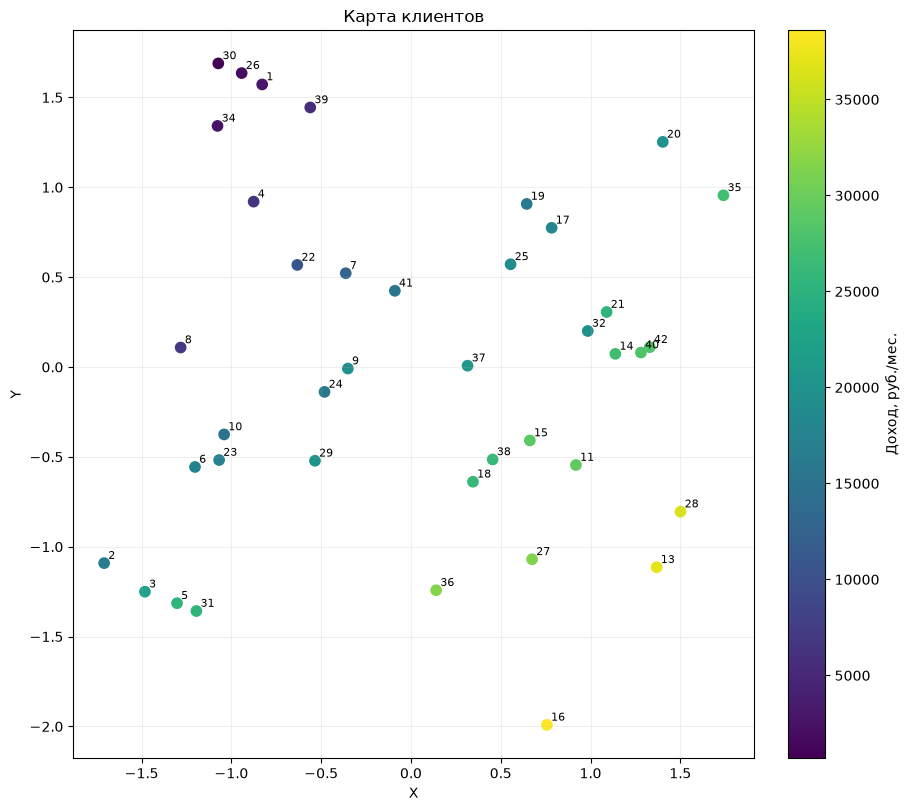

In [14]:
fig_map, ax = plt.subplots(figsize=(9, 8), layout="constrained")
points = ax.scatter(
    Z_mds[:, 0],
    Z_mds[:, 1],
    c=df_clean["Доход"].to_numpy(),
    s=55,
)
offset = (3, 3)
for client_id, (x, y) in zip(client_ids, Z_mds):
    ax.annotate(
        str(client_id),
        (x, y),
        xytext=offset,
        textcoords="offset points",
        fontsize=8,
    )

ax.set_title(f"Карта клиентов")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.grid(alpha=0.2)
colorbar = fig_map.colorbar(points, ax=ax)
colorbar.set_label("Доход, руб./мес.")
plt.show()

Выводы
- На карте заметен переход от клиентов с низкими доходами к клиентам
  с более высокими. Близкие точки приблизительно соответствуют похожим
  клиентам.
- Есть искажения расстояний. Близость на карте не гарантирует
  точного совпадения профилей, а видимые скопления сами по себе
  не доказывают наличие отдельных кластеров.

Получено приближенное размещение 40 клиентов на евклидовой плоскости.
Ненулевая ошибка согласуется с результатом пункта 9.